In [7]:
import pandas as pd
import statsmodels.formula.api as sm

In [2]:
campaigns = pd.read_csv('../data/northbound_campaigns.csv')

In [3]:
search = campaigns.loc[campaigns['channel'] == 'Search']
search.tail()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue
427,NB0428,2025-12-01,Search,0,9407.55,357833,13347,734,70266.21
431,NB0432,2025-12-08,Search,0,4691.81,173686,7544,373,35367.34
434,NB0435,2025-12-15,Search,0,11475.94,470610,17494,940,90259.37
437,NB0438,2025-12-22,Search,0,5827.12,296436,12601,574,51636.55
438,NB0439,2025-12-29,Search,0,4510.66,188606,7213,497,46921.79


In [8]:
search['impressions_k']  = search['impressions'] / 1000
search_model = sm.ols('conversions ~ impressions_k', data=search).fit()
print(search_model.summary())

                            OLS Regression Results                            
Dep. Variable:            conversions   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     444.9
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           1.38e-46
Time:                        15:07:32   Log-Likelihood:                -893.25
No. Observations:                 151   AIC:                             1790.
Df Residuals:                     149   BIC:                             1797.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         5.0398     16.835      0.299

In [9]:
search.tail()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue,impressions_k
427,NB0428,2025-12-01,Search,0,9407.55,357833,13347,734,70266.21,357.833
431,NB0432,2025-12-08,Search,0,4691.81,173686,7544,373,35367.34,173.686
434,NB0435,2025-12-15,Search,0,11475.94,470610,17494,940,90259.37,470.610
437,NB0438,2025-12-22,Search,0,5827.12,296436,12601,574,51636.55,296.436
438,NB0439,2025-12-29,Search,0,4510.66,188606,7213,497,46921.79,188.606


In [11]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

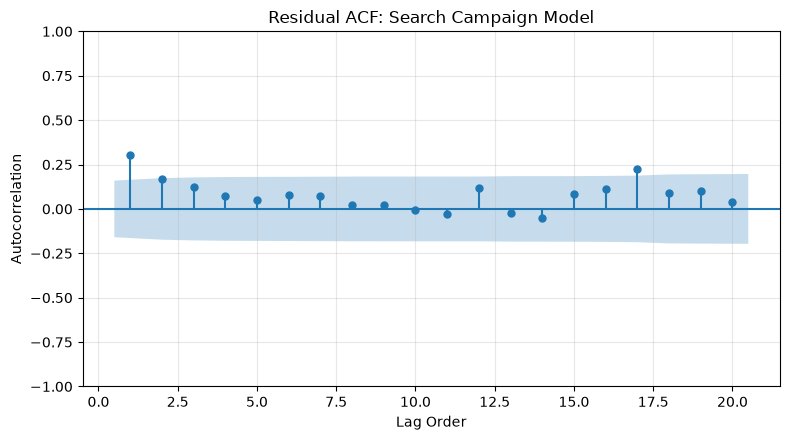

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_acf(search_model.resid, lags=20, zero=False, ax=ax)
ax.set_title('Residual ACF: Search Campaign Model')
ax.set_xlabel('Lag Order')
ax.set_ylabel('Autocorrelation')
ax.grid(True, alpha=.3)
plt.tight_layout()
plt.show()